# HOTEL BOOKING DATASET - A Comprehensive Exploratory Data Analysis

### About this notebook

This dataset contains 119390 observations for a City Hotel and a Resort Hotel. Each observation represents a hotel booking between the 1st of July 2015 and 31st of August 2017, including booking that effectively arrived and booking that were canceled.

Since this is hotel real data, all data elements pertaining hotel or costumer identification were deleted. Four Columns, 'name', 'email', 'phone number' and 'credit_card' have been artificially created and added to the dataset.

The data is originally from the article Hotel Booking Demand Datasets, written by Nuno Antonio, Ana Almeida, and Luis Nunes for Data in Brief, Volume 22, February 2019.

My data will be in front of the world's largest data science community. What questions do you want to see answered?


1. Which hotel type gets more bookings?
2. Which month has the highest number of bookings?
3. What is the average stay duration of guests?
4. Which hotel type has more cancellations?
5. Which customer type books the most rooms?
6. Which country has the highest number of bookings?

## Section 1 : Data Loading and Initial Inspection

In [ ]:
import pandas as pd
df = pd.read_csv('/content/hotel_bookings.csv')

print('Dataset loaded successfully.')
print(f'  Rows    : {df.shape[0]:,}')
print(f'  Columns : {df.shape[1]}')
print()
df.head()

Dataset loaded successfully.
  Rows    : 119,390
  Columns : 32



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
column_info = {
    'hotel'                     : 'name of the hotel',
    'is_canceled'               : 'whether any of the booking get cancelled or not',
    'lead_time'                 : 'time spent in hotel',
    'arrival_date_year'         : 'in which year the customer is arrived',
    'arrival_date_month'        : 'in which month the customer is arrived',
    'arrival_date_week_number'  : 'in which week the customer is arrived',
    'arrival_date_day_of_month' : 'on which day the customer is arrived',
    'stays_in_weekend_nights'   : 'how many nights the customer stayed during weekend',
    'stays_in_week_nights'      : 'how many nights the customer stayed during weeks',
    'adults'                    : 'how many adults are there',
    'deposit_type'              : 'what type of deposit the customer did',
    'agent'                     : 'agent no. (if any)',
    'company'                   : 'is there any company',
    'days_in_waiting_list'      : 'days_in_waiting_list',
    'customer_type'             : 'type of customer',
    'adr'                       : 'adr',
    'required_car_parking_spaces': 'how much car parking spaces is required',
    'total_of_special_requests'  : 'how much are special requests',
    'reservation_status'         : 'status of reservation',
    'reservation_status_date'    : 'date of reservation status'
    }
info_df = pd.DataFrame(list(column_info.items()), columns=['Column', 'Description'])
print(info_df.to_string(index=False))

                     Column                                        Description
                      hotel                                  name of the hotel
                is_canceled    whether any of the booking get cancelled or not
                  lead_time                                time spent in hotel
          arrival_date_year              in which year the customer is arrived
         arrival_date_month             in which month the customer is arrived
   arrival_date_week_number              in which week the customer is arrived
  arrival_date_day_of_month               on which day the customer is arrived
    stays_in_weekend_nights how many nights the customer stayed during weekend
       stays_in_week_nights   how many nights the customer stayed during weeks
                     adults                          how many adults are there
               deposit_type              what type of deposit the customer did
                      agent                         

In [ ]:
# Missing Values Overview
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df  = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df  = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('Missing Values Summary:')
print(missing_df)
print()
print('Basic Statistics:')
print(df.describe(include='all').T[['count', 'unique', 'top', 'freq']].dropna(how='all'))

Missing Values Summary:
          Missing Count  Missing %
company          112593      94.31
agent             16340      13.69
country             488       0.41
children              4       0.00

Basic Statistics:
                                   count unique         top    freq
hotel                             119390      2  City Hotel   79330
is_canceled                     119390.0    NaN         NaN     NaN
lead_time                       119390.0    NaN         NaN     NaN
arrival_date_year               119390.0    NaN         NaN     NaN
arrival_date_month                119390     12      August   13877
arrival_date_week_number        119390.0    NaN         NaN     NaN
arrival_date_day_of_month       119390.0    NaN         NaN     NaN
stays_in_weekend_nights         119390.0    NaN         NaN     NaN
stays_in_week_nights            119390.0    NaN         NaN     NaN
adults                          119390.0    NaN         NaN     NaN
children                        11

In [ ]:
# Convert reservation status date to datetime
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

# Extract useful date features
df['status_year']  = df['reservation_status_date'].dt.year
df['status_month'] = df['reservation_status_date'].dt.month
df['status_month_name'] = df['reservation_status_date'].dt.strftime('%B')

# Create total stay duration
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

# Create total guests column
df['total_guests'] = (
    df['adults'] +
    df['children'].fillna(0) +
    df['babies']
)

# Handle missing values
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)
df['children'] = df['children'].fillna(0)

# Create booking status labels
df['booking_status'] = df['is_canceled'].map({
    0: 'Not Canceled',
    1: 'Canceled'
})

# Extract arrival season
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['arrival_season'] = df['arrival_date_month'].map({
    'January': 'Winter',
    'February': 'Winter',
    'March': 'Spring',
    'April': 'Spring',
    'May': 'Spring',
    'June': 'Summer',
    'July': 'Summer',
    'August': 'Summer',
    'September': 'Autumn',
    'October': 'Autumn',
    'November': 'Autumn',
    'December': 'Winter'
})

# Primary meal type cleanup
df['meal'] = df['meal'].replace('Undefined', 'SC')

# Average guests per room-night
df['guests_per_night'] = df['total_guests'] / df['total_nights'].replace(0, 1)

print("Preprocessing complete.")

print(
    f"Reservation status date range: "
    f"{df['reservation_status_date'].min().date()} "
    f"to {df['reservation_status_date'].max().date()}"
)

print(
    f"Arrival year range: "
    f"{df['arrival_date_year'].min()} "
    f"to {df['arrival_date_year'].max()}"
)

print(
    f"Total bookings: {len(df)}"
)

Preprocessing complete.
Reservation status date range: 2014-10-17 to 2017-09-14
Arrival year range: 2015 to 2017
Total bookings: 119390


In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,reservation_status,reservation_status_date,status_year,status_month,status_month_name,total_nights,total_guests,booking_status,arrival_season,guests_per_night
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Check-Out,2015-07-01,2015,7,July,0,2.0,Not Canceled,Summer,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Check-Out,2015-07-01,2015,7,July,0,2.0,Not Canceled,Summer,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Check-Out,2015-07-02,2015,7,July,1,1.0,Not Canceled,Summer,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Check-Out,2015-07-02,2015,7,July,1,1.0,Not Canceled,Summer,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Check-Out,2015-07-03,2015,7,July,2,2.0,Not Canceled,Summer,1.0


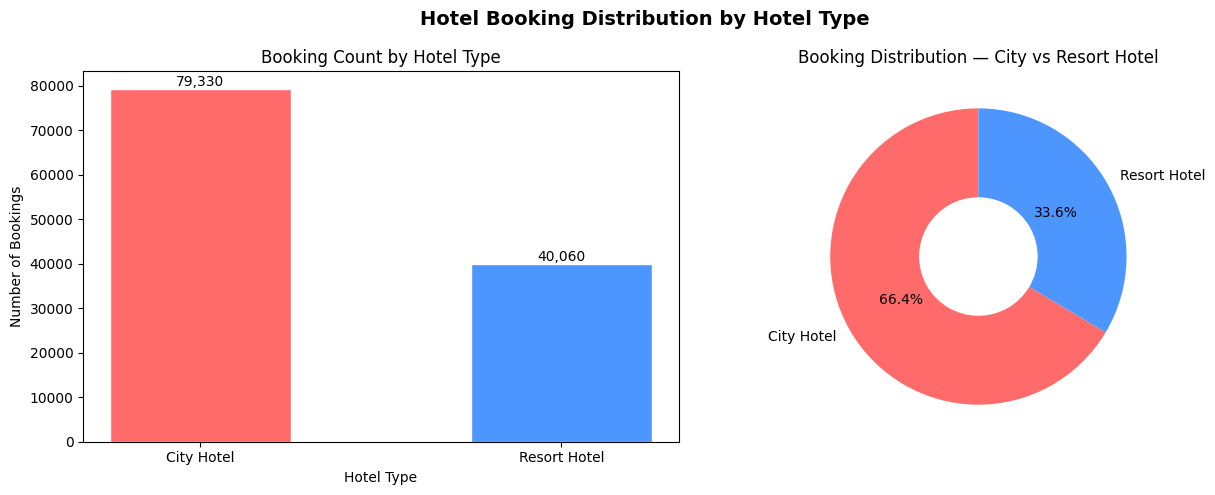

City Hotel   : 79,330 bookings (66.4%)
Resort Hotel : 40,060 bookings (33.6%)


In [ ]:
# Count hotel types
hotel_counts = df['hotel'].value_counts()
hotel_pct = (hotel_counts / len(df) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
bars = axes[0].bar(
    hotel_counts.index,
    hotel_counts.values,
    color=['#FF6B6B', '#4D96FF'],
    edgecolor='white',
    width=0.5
)

axes[0].set_title('Booking Count by Hotel Type')
axes[0].set_ylabel('Number of Bookings')
axes[0].set_xlabel('Hotel Type')

# Add labels on bars
for bar in bars:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom'
    )

# Donut chart
wedges, texts, autotexts = axes[1].pie(
    hotel_counts.values,
    labels=hotel_counts.index,
    colors=['#FF6B6B', '#4D96FF'],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.6)
)

axes[1].set_title('Booking Distribution — City vs Resort Hotel')

fig.suptitle(
    'Hotel Booking Distribution by Hotel Type',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Print summary
print(f'City Hotel   : {hotel_counts["City Hotel"]:,} bookings ({hotel_pct["City Hotel"]}%)')
print(f'Resort Hotel : {hotel_counts["Resort Hotel"]:,} bookings ({hotel_pct["Resort Hotel"]}%)')

In [ ]:
df.groupby(['arrival_date_year', 'hotel']).size().unstack()

hotel,City Hotel,Resort Hotel
arrival_date_year,,
2015,13682,8314
2016,38140,18567
2017,27508,13179


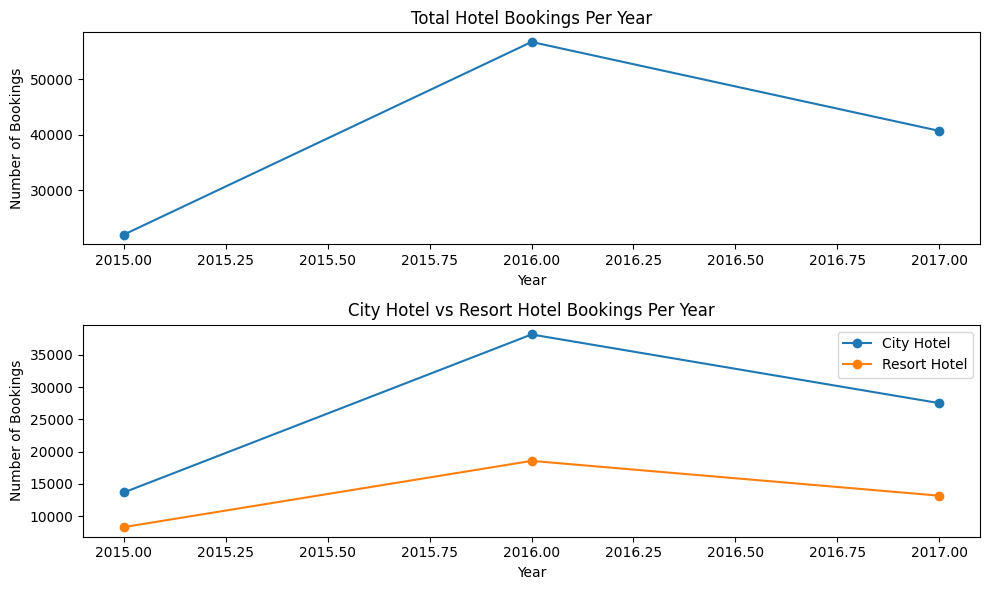

Peak booking year : 2016 (56,707 bookings)
Insight: The dataset shows yearly booking demand trends for both city and resort hotels, helping analyze seasonality, customer behavior, and hotel popularity over time.


In [ ]:
# Group by arrival year and hotel type
yearly = df.groupby(['arrival_date_year', 'hotel']).size().unstack(fill_value=0)

# Optional filter (dataset mainly contains 2015–2017)
yearly = yearly[yearly.index >= 2015]

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# Total bookings per year
yearly_total = yearly.sum(axis=1)

axes[0].plot(
    yearly_total.index,
    yearly_total.values,
    marker='o'
)

axes[0].set_title('Total Hotel Bookings Per Year')
axes[0].set_ylabel('Number of Bookings')
axes[0].set_xlabel('Year')

# City vs Resort Hotel bookings per year
if 'City Hotel' in yearly.columns and 'Resort Hotel' in yearly.columns:

    axes[1].plot(
        yearly.index,
        yearly['City Hotel'],
        marker='o',
        label='City Hotel'
    )

    axes[1].plot(
        yearly.index,
        yearly['Resort Hotel'],
        marker='o',
        label='Resort Hotel'
    )

    axes[1].set_title('City Hotel vs Resort Hotel Bookings Per Year')
    axes[1].set_ylabel('Number of Bookings')
    axes[1].set_xlabel('Year')
    axes[1].legend()

plt.tight_layout()
plt.show()

# Peak booking year
peak_year = yearly_total.idxmax()

print(
    f'Peak booking year : '
    f'{peak_year} ({yearly_total[peak_year]:,} bookings)'
)

print(
    'Insight: The dataset shows yearly booking demand trends '
    'for both city and resort hotels, helping analyze '
    'seasonality, customer behavior, and hotel popularity over time.'
)

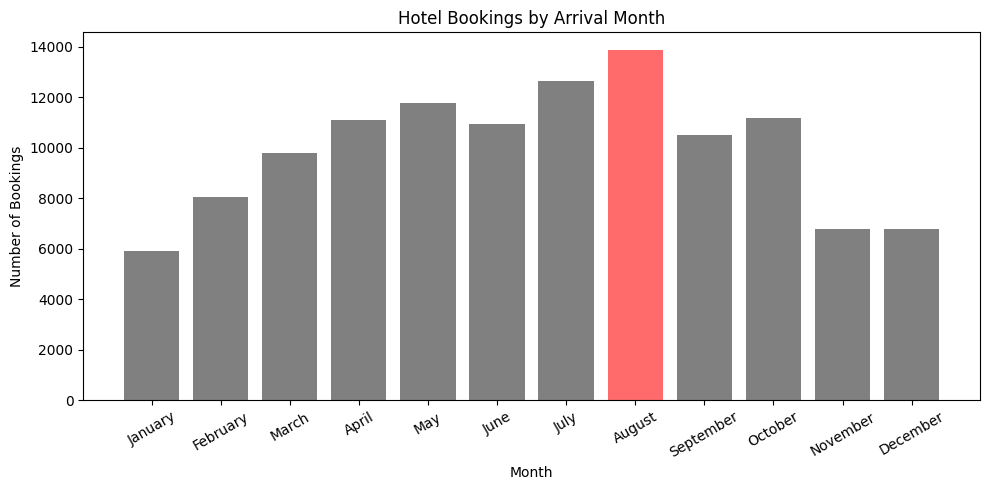

Peak booking month: August (13,877 bookings)
Insight: Monthly booking trends help identify seasonal demand patterns and peak travel periods.


In [ ]:
# Define month order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

# Count bookings per arrival month
monthly = (
    df['arrival_date_month']
    .value_counts()
    .reindex(month_order)
    .fillna(0)
)

# Identify peak booking month
peak_month = monthly.idxmax()

# Highlight peak month
colors = [
    '#FF6B6B' if m == peak_month else 'gray'
    for m in monthly.index
]

# Plot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    monthly.index,
    monthly.values,
    color=colors
)

ax.set_title('Hotel Bookings by Arrival Month')
ax.set_ylabel('Number of Bookings')
ax.set_xlabel('Month')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Print insight
print(
    f'Peak booking month: '
    f'{peak_month} ({int(monthly[peak_month]):,} bookings)'
)

print(
    'Insight: Monthly booking trends help identify '
    'seasonal demand patterns and peak travel periods.'
)

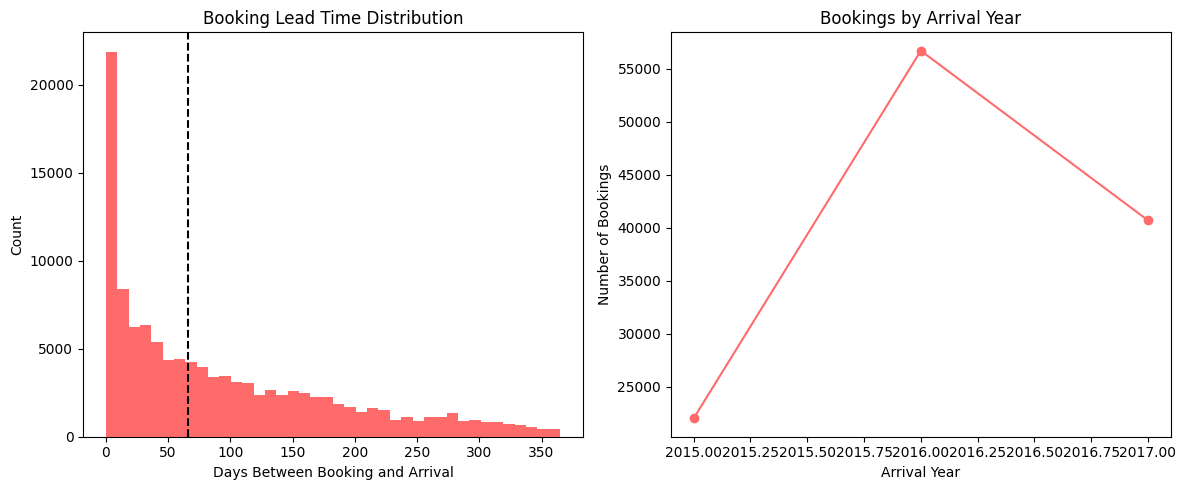

Median booking lead time: 66 days
Year with most bookings: 2016


In [ ]:
import matplotlib.pyplot as plt

# Clean dataset
df_clean = df.dropna(subset=['lead_time', 'arrival_date_year'])

# Keep reasonable lead times
df_clean = df_clean[
    (df_clean['lead_time'] >= 0) &
    (df_clean['lead_time'] <= 365)
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Lead time distribution
axes[0].hist(
    df_clean['lead_time'],
    bins=40,
    color='#FF6B6B'
)

axes[0].set_title('Booking Lead Time Distribution')
axes[0].set_xlabel('Days Between Booking and Arrival')
axes[0].set_ylabel('Count')

# Median line
axes[0].axvline(
    df_clean['lead_time'].median(),
    color='black',
    linestyle='--',
    linewidth=1.5
)

# Bookings by arrival year
arrival_counts = (
    df['arrival_date_year']
    .value_counts()
    .sort_index()
)

axes[1].plot(
    arrival_counts.index,
    arrival_counts.values,
    marker='o',
    color='#FF6B6B'
)

axes[1].set_title('Bookings by Arrival Year')
axes[1].set_xlabel('Arrival Year')
axes[1].set_ylabel('Number of Bookings')

plt.tight_layout()
plt.show()

# Summary statistics
print(
    f'Median booking lead time: '
    f'{df_clean["lead_time"].median():.0f} days'
)

print(
    f'Year with most bookings: '
    f'{arrival_counts.idxmax()}'
)

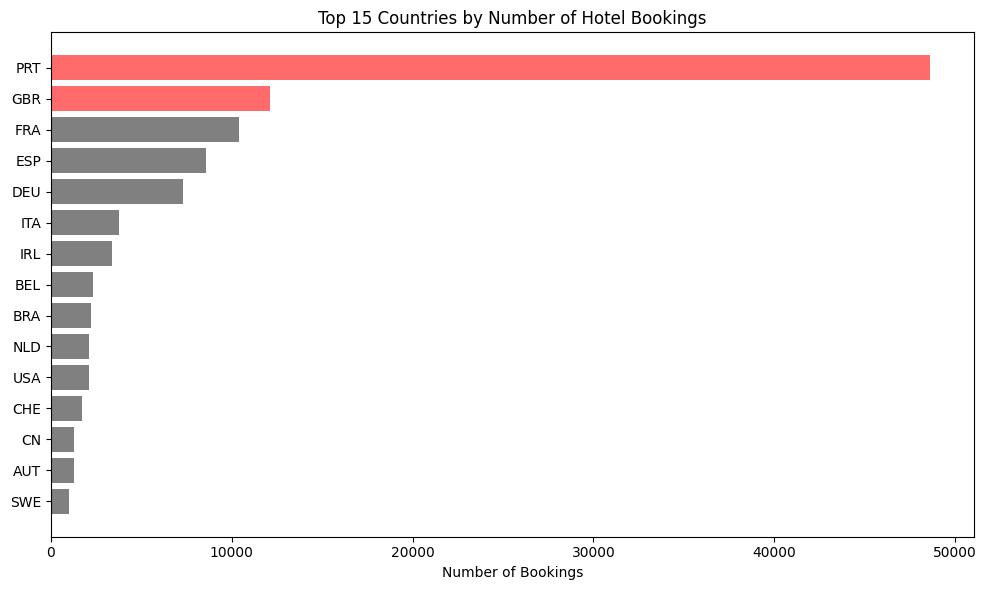

Top guest country: PRT (48,590 bookings)
Top 5 countries account for 72.9% of all bookings


In [ ]:
# Top 15 guest countries
country_counts = (
    df['country']
    .fillna('Unknown')
    .value_counts()
    .head(15)
)

# Highlight top 2 countries
colors = [
    '#FF6B6B' if i < 2 else 'gray'
    for i in range(len(country_counts))
]

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    country_counts.index[::-1],
    country_counts.values[::-1],
    color=colors[::-1]
)

ax.set_title('Top 15 Countries by Number of Hotel Bookings')
ax.set_xlabel('Number of Bookings')

plt.tight_layout()
plt.show()

# Insights
top_country = country_counts.index[0]
top_val = country_counts.iloc[0]

print(
    f'Top guest country: '
    f'{top_country} ({top_val:,} bookings)'
)

print(
    f'Top 5 countries account for '
    f'{country_counts.head(5).sum() / df["country"].notna().sum() * 100:.1f}% '
    f'of all bookings'
)

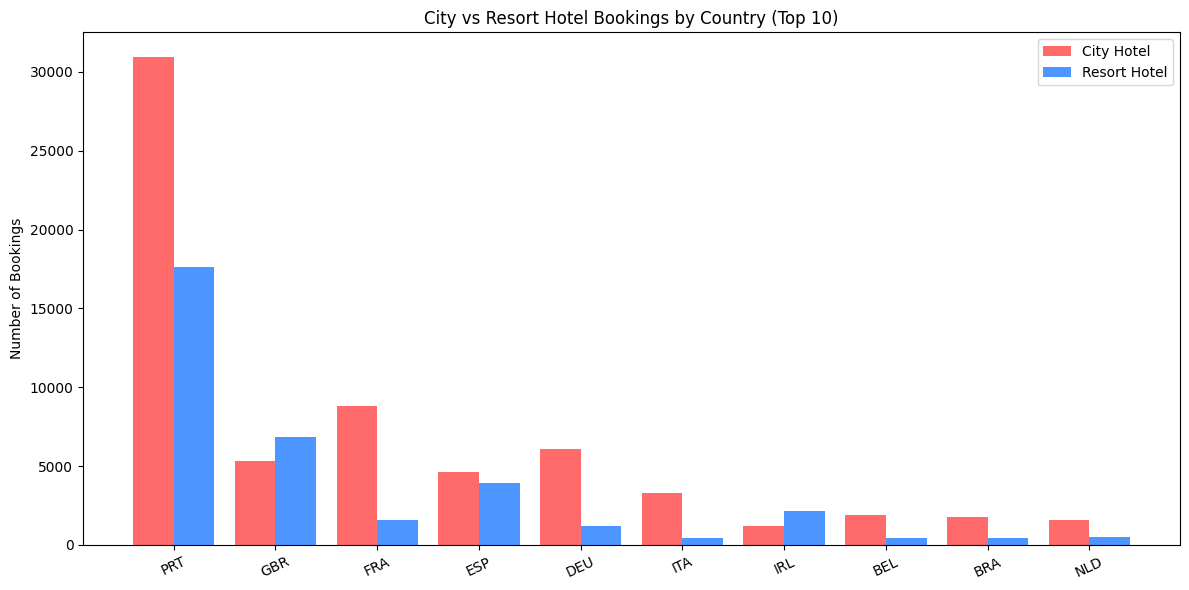

Insight: PRT contributes the highest number of hotel bookings.
The comparison highlights differences in traveler preferences between city hotels and resort hotels across countries.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Top 10 guest countries
top10_countries = (
    df['country']
    .dropna()
    .value_counts()
    .head(10)
    .index
)

# Group by country and hotel type
country_hotel = (
    df[df['country'].isin(top10_countries)]
    .groupby(['country', 'hotel'])
    .size()
    .unstack(fill_value=0)
)

# Preserve ranking order
country_hotel = country_hotel.loc[top10_countries]

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(country_hotel))
w = 0.4

# City Hotel bars
if 'City Hotel' in country_hotel.columns:
    ax.bar(
        x - w/2,
        country_hotel['City Hotel'],
        w,
        label='City Hotel',
        color='#FF6B6B'
    )

# Resort Hotel bars
if 'Resort Hotel' in country_hotel.columns:
    ax.bar(
        x + w/2,
        country_hotel['Resort Hotel'],
        w,
        label='Resort Hotel',
        color='#4D96FF'
    )

# Labels
ax.set_title('City vs Resort Hotel Bookings by Country (Top 10)')
ax.set_ylabel('Number of Bookings')

ax.set_xticks(x)
ax.set_xticklabels(country_hotel.index, rotation=25)

ax.legend()

plt.tight_layout()
plt.show()

# Insights
top_country = top10_countries[0]

print(
    f'Insight: {top_country} contributes the highest number of hotel bookings.'
)

print(
    'The comparison highlights differences in traveler preferences '
    'between city hotels and resort hotels across countries.'
)

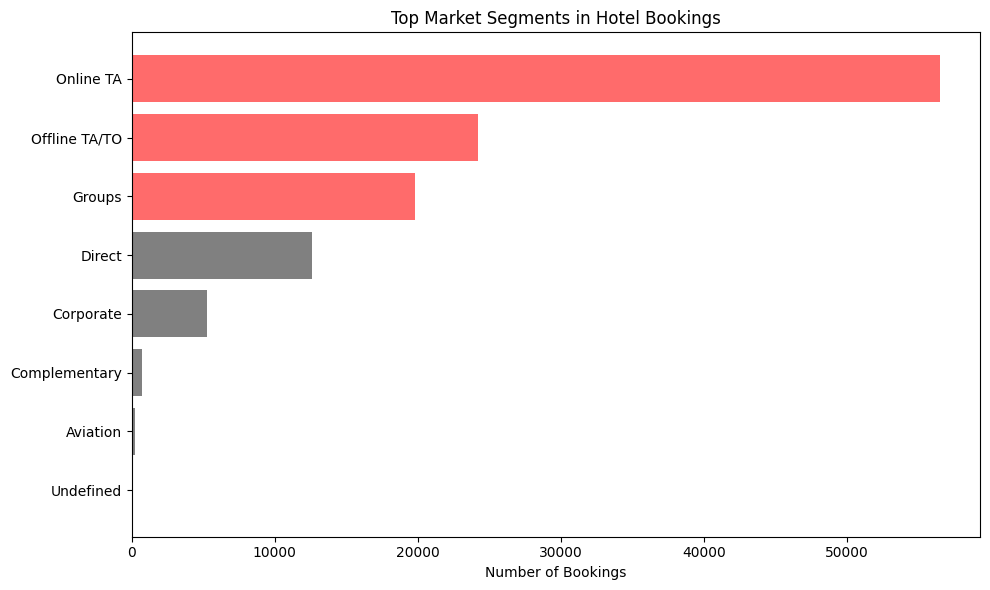

Most common market segment: Online TA (56,477 bookings)
Top 3 market segments account for 100,507 bookings


In [ ]:
# Count market segments
segment_counts = (
    df['market_segment']
    .dropna()
    .value_counts()
    .head(20)
)

# Highlight top 3 segments
colors = [
    '#FF6B6B' if i < 3 else 'gray'
    for i in range(len(segment_counts))
]

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    segment_counts.index[::-1],
    segment_counts.values[::-1],
    color=colors[::-1]
)

ax.set_title('Top Market Segments in Hotel Bookings')
ax.set_xlabel('Number of Bookings')

plt.tight_layout()
plt.show()

# Insights
print(
    f'Most common market segment: '
    f'{segment_counts.index[0]} '
    f'({segment_counts.iloc[0]:,} bookings)'
)

print(
    f'Top 3 market segments account for '
    f'{segment_counts.head(3).sum():,} bookings'
)

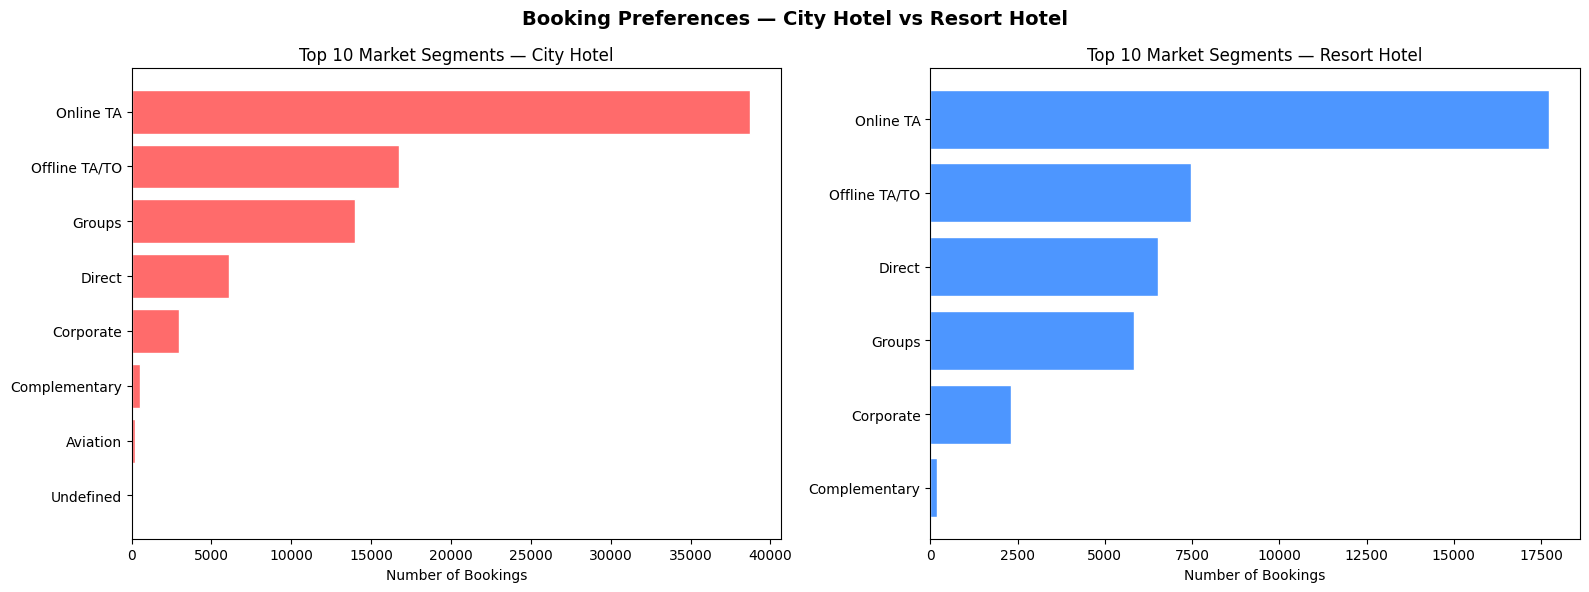

In [ ]:
# Market segments by hotel type
city_segments = (
    df[df['hotel'] == 'City Hotel']['market_segment']
    .dropna()
    .value_counts()
    .head(10)
)

resort_segments = (
    df[df['hotel'] == 'Resort Hotel']['market_segment']
    .dropna()
    .value_counts()
    .head(10)
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# City Hotel segments
axes[0].barh(
    city_segments.index[::-1],
    city_segments.values[::-1],
    color='#FF6B6B',
    edgecolor='white'
)

axes[0].set_title('Top 10 Market Segments — City Hotel')
axes[0].set_xlabel('Number of Bookings')

# Resort Hotel segments
axes[1].barh(
    resort_segments.index[::-1],
    resort_segments.values[::-1],
    color='#4D96FF',
    edgecolor='white'
)

axes[1].set_title('Top 10 Market Segments — Resort Hotel')
axes[1].set_xlabel('Number of Bookings')

# Main title
fig.suptitle(
    'Booking Preferences — City Hotel vs Resort Hotel',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [ ]:
df["customer_type"].unique()

array(['Transient', 'Contract', 'Transient-Party', 'Group'], dtype=object)

In [ ]:
df["reservation_status"].unique()

array(['Check-Out', 'Canceled', 'No-Show'], dtype=object)

In [ ]:
categorical_cols = [
    'hotel',
    'meal',
    'market_segment',
    'distribution_channel',
    'deposit_type',
    'customer_type',
    'reservation_status'
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


hotel:
['Resort Hotel' 'City Hotel']

meal:
['BB' 'FB' 'HB' 'SC']

market_segment:
['Direct' 'Corporate' 'Online TA' 'Offline TA/TO' 'Complementary' 'Groups'
 'Undefined' 'Aviation']

distribution_channel:
['Direct' 'Corporate' 'TA/TO' 'Undefined' 'GDS']

deposit_type:
['No Deposit' 'Refundable' 'Non Refund']

customer_type:
['Transient' 'Contract' 'Transient-Party' 'Group']

reservation_status:
['Check-Out' 'Canceled' 'No-Show']


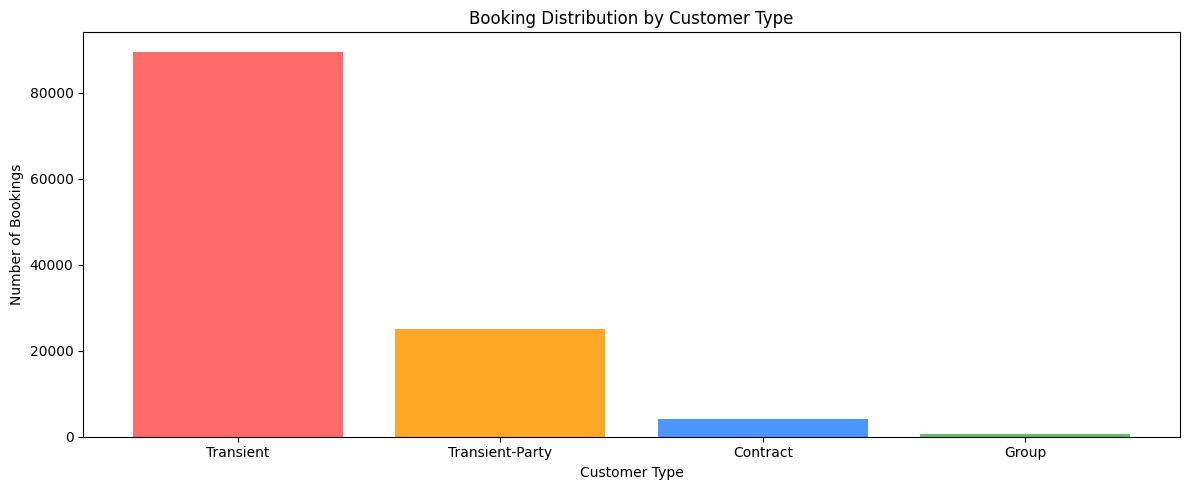

Transient bookings: 89,613 (75.1%)


In [ ]:
# Valid customer types
valid_customer_types = [
    'Transient',
    'Transient-Party',
    'Contract',
    'Group'
]

df_customers = df[df['customer_type'].isin(valid_customer_types)]

# Order customer types
customer_order = [
    'Transient',
    'Transient-Party',
    'Contract',
    'Group'
]

customer_counts = (
    df_customers['customer_type']
    .value_counts()
    .reindex(customer_order)
)

# Color map
color_map = {
    'Transient': '#FF6B6B',
    'Transient-Party': '#FFA726',
    'Contract': '#4D96FF',
    'Group': '#66BB6A'
}

bar_colors = [
    color_map.get(c, '#9E9E9E')
    for c in customer_counts.index
]

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    customer_counts.index,
    customer_counts.values,
    color=bar_colors
)

ax.set_title('Booking Distribution by Customer Type')
ax.set_ylabel('Number of Bookings')
ax.set_xlabel('Customer Type')

plt.tight_layout()
plt.show()

# Insights
transient_count = (
    df_customers[df_customers['customer_type'] == 'Transient']
    .shape[0]
)

total_customers = df_customers.shape[0]

print(
    f'Transient bookings: '
    f'{transient_count:,} '
    f'({transient_count / total_customers * 100:.1f}%)'
)

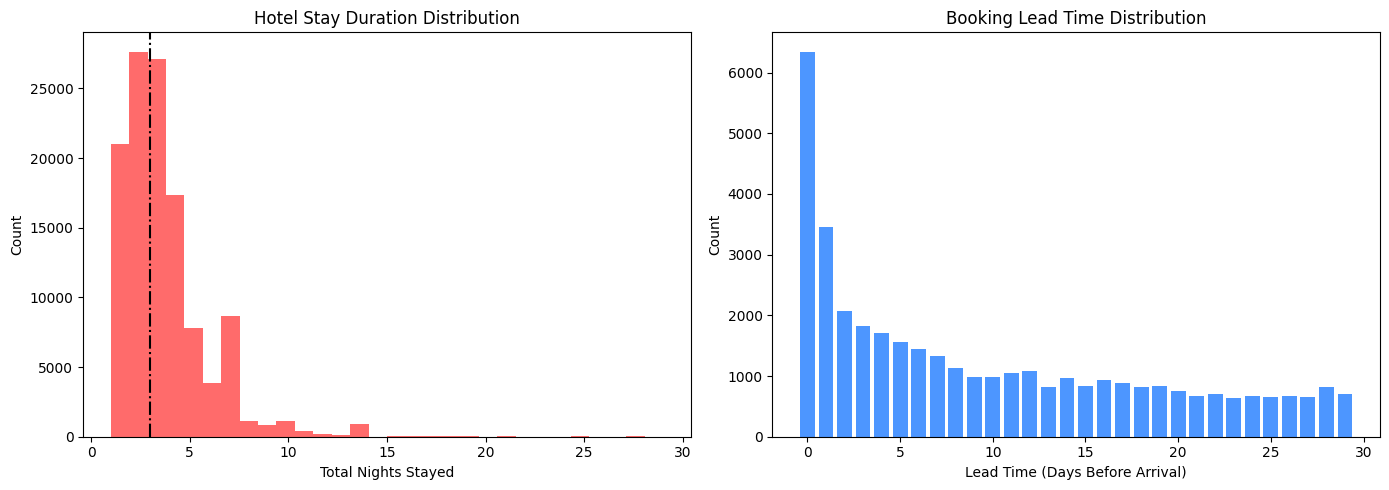

Average stay duration : 3.4 nights
Median stay duration  : 3 nights
Short stays (≤2 nights): 48,663 (41.0%)


In [ ]:
import matplotlib.pyplot as plt

# Total stay duration
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

# Filter reasonable stay durations
stay_dur = df[df['total_nights'].notna()]
stay_dur = stay_dur[
    (stay_dur['total_nights'] > 0) &
    (stay_dur['total_nights'] < 30)
]

# Lead time distribution
lead_time = df[df['lead_time'].notna()]
lead_time = lead_time[
    (lead_time['lead_time'] >= 0) &
    (lead_time['lead_time'] <= 365)
]

# Lead-time frequency
lead_bins = (
    lead_time['lead_time']
    .round()
    .value_counts()
    .sort_index()
    .head(30)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stay duration histogram
axes[0].hist(
    stay_dur['total_nights'],
    bins=30,
    color='#FF6B6B'
)

axes[0].set_title('Hotel Stay Duration Distribution')
axes[0].set_xlabel('Total Nights Stayed')
axes[0].set_ylabel('Count')

# Median line
axes[0].axvline(
    stay_dur['total_nights'].median(),
    color='black',
    linestyle='-.',
    linewidth=1.5
)

# Lead time distribution
axes[1].bar(
    lead_bins.index.astype(int),
    lead_bins.values,
    color='#4D96FF'
)

axes[1].set_title('Booking Lead Time Distribution')
axes[1].set_xlabel('Lead Time (Days Before Arrival)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Insights
print(
    f'Average stay duration : '
    f'{stay_dur["total_nights"].mean():.1f} nights'
)

print(
    f'Median stay duration  : '
    f'{stay_dur["total_nights"].median():.0f} nights'
)

short_stays = (stay_dur['total_nights'] <= 2).sum()

print(
    f'Short stays (≤2 nights): '
    f'{short_stays:,} '
    f'({short_stays / len(stay_dur) * 100:.1f}%)'
)

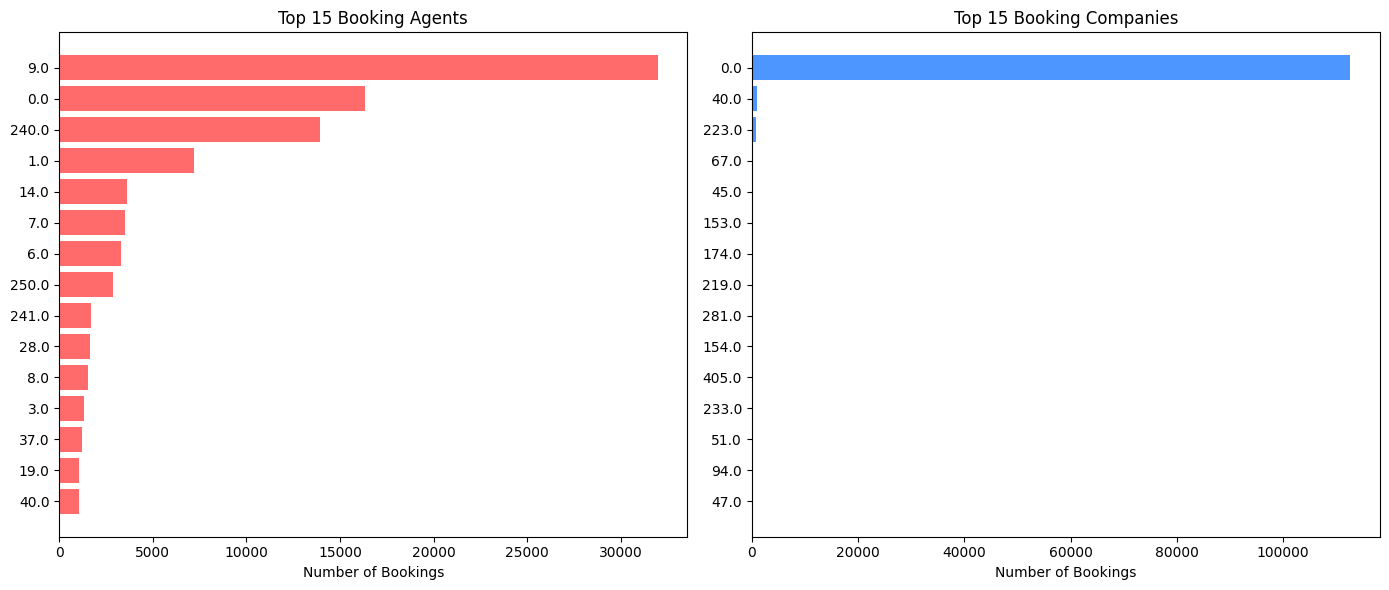

In [ ]:
import matplotlib.pyplot as plt

# Top 15 booking agents
top_agents = (
    df['agent']
    .dropna()
    .astype(str)
    .value_counts()
    .head(15)
)

# Remove '0' if you used fillna(0)
top_agents = top_agents[top_agents.index != '0']

# Top 15 booking companies
top_companies = (
    df['company']
    .dropna()
    .astype(str)
    .value_counts()
    .head(15)
)

# Remove '0' if you used fillna(0)
top_companies = top_companies[top_companies.index != '0']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Booking agents
axes[0].barh(
    top_agents.index[::-1],
    top_agents.values[::-1],
    color='#FF6B6B'
)

axes[0].set_title('Top 15 Booking Agents')
axes[0].set_xlabel('Number of Bookings')

# Booking companies
axes[1].barh(
    top_companies.index[::-1],
    top_companies.values[::-1],
    color='#4D96FF'
)

axes[1].set_title('Top 15 Booking Companies')
axes[1].set_xlabel('Number of Bookings')

plt.tight_layout()
plt.show()

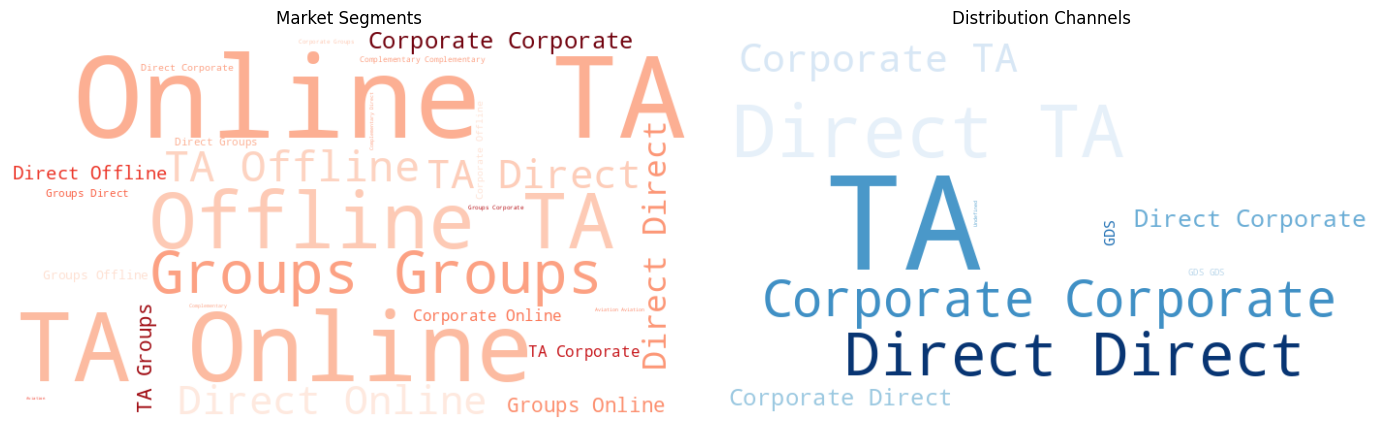

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Combine market segment text
all_segments = ' '.join(
    df['market_segment']
    .dropna()
    .astype(str)
    .tolist()
)

# Combine distribution channel text
all_channels = ' '.join(
    df['distribution_channel']
    .dropna()
    .astype(str)
    .tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Market Segment Word Cloud
wc_segments = WordCloud(
    width=700,
    height=400,
    background_color='white',
    colormap='Reds',
    max_words=100
).generate(all_segments)

axes[0].imshow(wc_segments, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Market Segments')

# Distribution Channel Word Cloud
wc_channels = WordCloud(
    width=700,
    height=400,
    background_color='white',
    colormap='Blues',
    max_words=100
).generate(all_channels)

axes[1].imshow(wc_channels, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Distribution Channels')

plt.tight_layout()
plt.show()